# LDA Baseline Model — Page Level
**Modeling**

Implements a Latent Dirichlet Allocation (LDA) baseline following the CRISP-DM modeling phase.  
Library: `tomotopy` (Collapsed Gibbs Sampling).  
Input: page-level token lists produced by `src/utils.py`.  
Granularity: one document = one slide page (≥ 10 tokens after preprocessing).  
Split: 90/10 holdout (108 train / 13 test, `random_state=42`).

**Structure:**
1. Setup & Data Loading
2. Corpus Preparation (train/test split)
3. Model Training
4. Topic Inspection
5. Initial Evaluation (C_v)
6. Grid Search — Finding the Best K
7. Cross-library Comparison
8. Final Evaluation (C_v, perplexity, diversity, cosine similarity, entropy, exclusivity)

## 1. Setup & Data Loading

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

_nb_dir = os.path.dirname(os.path.abspath('lda.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)

warnings.filterwarnings('ignore')

# Plotting defaults
plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'font.family'      : 'serif',
})
PALETTE = ['#2C5F8A', '#4C9BE8', '#A8C8E8', '#D9E8F5']

print('Libraries loaded.')

Libraries loaded.


In [2]:
from utils import load_corpus, tokenize_corpus, build_slide_page_docs

# Load and Tokenize corpus
corpus = tokenize_corpus(load_corpus())

# Aggregate to page level. Drop pages with fewer than 10 tokens
MIN_TOKENS = 10
docs = build_slide_page_docs(corpus)
docs = docs[docs['n_tokens'] >= MIN_TOKENS].reset_index(drop=True)

print(f'Documents (pages): {len(docs)}')
print(f'Token count — min: {docs.n_tokens.min()}, median: {docs.n_tokens.median():.0f}, max: {docs.n_tokens.max()}')
docs.head()

Dropping 6 empty pages after tokenisation.


Documents (pages): 121
Token count — min: 10, median: 21, max: 69


,source_file,page,tokens,n_tokens
0,icd_1_v1_cleaned_v7.csv,5,"[logístico, conteúdo, informação, plataforma, ...",24
1,icd_1_v1_cleaned_v7.csv,6,"[unidade, curricular, objetivo, contacto, ciên...",39
2,icd_1_v1_cleaned_v7.csv,7,"[processo, pedagógico, aplicação, prático, est...",26
3,icd_1_v1_cleaned_v7.csv,8,"[sucesso, capaz, necessidade, existência, prát...",27
4,icd_1_v1_cleaned_v7.csv,9,"[avaliação, avaliação, periódico, modalidade, ...",33


In [3]:
print(f"Documents: {len(docs)}")
print(f"Total tokens: {docs.n_tokens.sum()}")
print(f"Mean tokens per document: {docs.n_tokens.mean():.1f}")
print(f"Median tokens per document: {docs.n_tokens.median():.1f}")
print(f"Min tokens: {docs.n_tokens.min()}")
print(f"Max tokens: {docs.n_tokens.max()}")

Documents: 121
Total tokens: 2894
Mean tokens per document: 23.9
Median tokens per document: 21.0
Min tokens: 10
Max tokens: 69


## 2. Corpus Preparation

In [4]:
import tomotopy as tp
from tomotopy.coherence import Coherence

RANDOM_SEED = 42

texts = docs['tokens'].tolist()

print(f'Corpus size: {len(texts)} documents')
print(f'tomotopy version: {tp.__version__}')

Corpus size: 121 documents
tomotopy version: 0.14.0


In [5]:
from sklearn.model_selection import train_test_split

# 90/10 holdout split — model trained only on train set; test set used for perplexity evaluation
train_df, test_df = train_test_split(docs, test_size=0.10, random_state=RANDOM_SEED)
train_df    = train_df.reset_index(drop=True)
test_df     = test_df.reset_index(drop=True)
train_texts = train_df['tokens'].tolist()
test_texts  = test_df['tokens'].tolist()

print(f'Train: {len(train_texts)} docs | Test: {len(test_texts)} docs')

Train: 108 docs | Test: 13 docs


## 3. Model Training

In [6]:
NUM_TOPICS  = 9     # initial number of topics for LDA; based on number of slide decks
ITERATIONS  = 1000
ALPHA       = 0.1
ETA         = 0.01

lda = tp.LDAModel(
    k        = NUM_TOPICS,
    alpha    = ALPHA,
    eta      = ETA,
    min_df   = 2,
    rm_top   = 0,
    seed     = RANDOM_SEED,
)

for token_list in train_texts:
    lda.add_doc(token_list)

lda.train(0)
lda.train(ITERATIONS, workers=1)

print(f'LDA trained: {lda.k} topics, {ITERATIONS} iterations, seed={RANDOM_SEED}')
print(f'Vocabulary: {lda.num_vocabs} terms')

LDA trained: 9 topics, 1000 iterations, seed=42
Vocabulary: 373 terms


## 4. Topic Inspection

In [7]:
# Top terms per topic
TOP_N = 10
for i in range(NUM_TOPICS):
    terms = lda.get_topic_words(i, top_n=TOP_N)
    term_str = ' + '.join(f'{p:.3f}*"{w}"' for w, p in terms)
    print(f'Topic {i+1}: {term_str}')

Topic 1: 0.070*"processo" + 0.059*"objetivo" + 0.048*"ciência" + 0.040*"problema" + 0.026*"desempenho" + 0.026*"modelação" + 0.026*"técnica" + 0.026*"caso" + 0.022*"estudante" + 0.022*"extração"
Topic 2: 0.078*"cluster" + 0.062*"passo" + 0.062*"distância" + 0.047*"clustering" + 0.039*"learning" + 0.039*"observação" + 0.031*"média" + 0.031*"semelhante" + 0.031*"ligação" + 0.031*"information"
Topic 3: 0.059*"gráfico" + 0.051*"classificação" + 0.051*"false" + 0.051*"taxa" + 0.051*"rate" + 0.042*"registo" + 0.042*"matriz" + 0.042*"positive" + 0.034*"actual" + 0.034*"confusão"
Topic 4: 0.121*"visualização" + 0.053*"cliente" + 0.038*"população" + 0.038*"amostra" + 0.030*"apresentação" + 0.030*"ferramenta" + 0.030*"comunicação" + 0.030*"função" + 0.030*"específico" + 0.030*"sequência"
Topic 5: 0.121*"conjunto" + 0.070*"treino" + 0.057*"algoritmo" + 0.057*"classificação" + 0.051*"decisão" + 0.051*"árvore" + 0.044*"teste" + 0.044*"features" + 0.038*"classe" + 0.038*"dataset"
Topic 6: 0.144*"mod

In [8]:
from utils import generate_topic_labels_llm

TOPIC_LABELS = generate_topic_labels_llm(lda, NUM_TOPICS)

for i, label in TOPIC_LABELS.items():
    print(f'T{i+1}: {label}')

T1: Introdução à Ciência de Dados
T2: Modelação Não Supervisionada
T3: Matriz de Confusão
T4: Visualização e Comunicação
T5: Modelação Supervisionada
T6: Modelação Supervisionada
T7: Data quality and analysis
T8: Preparação e análise de dados
T9: Ética e privacidade dos dados


In [9]:
# Topic summary table
rows = []
for i in range(NUM_TOPICS):
    terms = lda.get_topic_words(i, top_n=TOP_N)
    top_words_list = [w for w, _ in terms]
    top_words = ', '.join(top_words_list)
    top_weights = [round(p, 3) for _, p in terms]
    rows.append({
        'Topic': f'T{i+1}',
        'Label': TOPIC_LABELS[i],
        'Top 10 Terms': top_words,
        'Top word': top_words_list[0],
        'Max weight': max(top_weights),
    })

topic_df = pd.DataFrame(rows).set_index('Topic')

topic_df.style \
    .set_caption('LDA Topics — Top 10 Terms per Topic (Library: tomotopy)') \
    .set_properties(**{'text-align': 'left'}) \
    .bar(subset=['Max weight'], color='#0156AB', vmin=0, vmax=0.15)

,Label,Top 10 Terms,Top word,Max weight
Topic,,,,
T1,Introdução à Ciência de Dados,"processo, objetivo, ciência, problema, desempenho, modelação, técnica, caso, estudante, extração",processo,0.070000
T2,Modelação Não Supervisionada,"cluster, passo, distância, clustering, learning, observação, média, semelhante, ligação, information",cluster,0.078000
T3,Matriz de Confusão,"gráfico, classificação, false, taxa, rate, registo, matriz, positive, actual, confusão",gráfico,0.059000
T4,Visualização e Comunicação,"visualização, cliente, população, amostra, apresentação, ferramenta, comunicação, função, específico, sequência",visualização,0.121000
T5,Modelação Supervisionada,"conjunto, treino, algoritmo, classificação, decisão, árvore, teste, features, classe, dataset",conjunto,0.121000
T6,Modelação Supervisionada,"modelo, resultado, regressão, padrão, previsão, base, aprendizagem, avaliação, generativo, artificial",modelo,0.144000
T7,Data quality and analysis,"valores, atributo, análise, informação, conhecimento, outlier, contexto, omisso, qualidade, erro",valores,0.087000
T8,Preparação e análise de dados,"variável, numérico, categórico, imagem, aluno, conteúdo, correlação, transformação, texto, logístico",variável,0.140000
T9,Ética e privacidade dos dados,"informação, direito, tratamento, europeu, privacidade, empresa, proteção, titulares, pessoal, volume",informação,0.061000


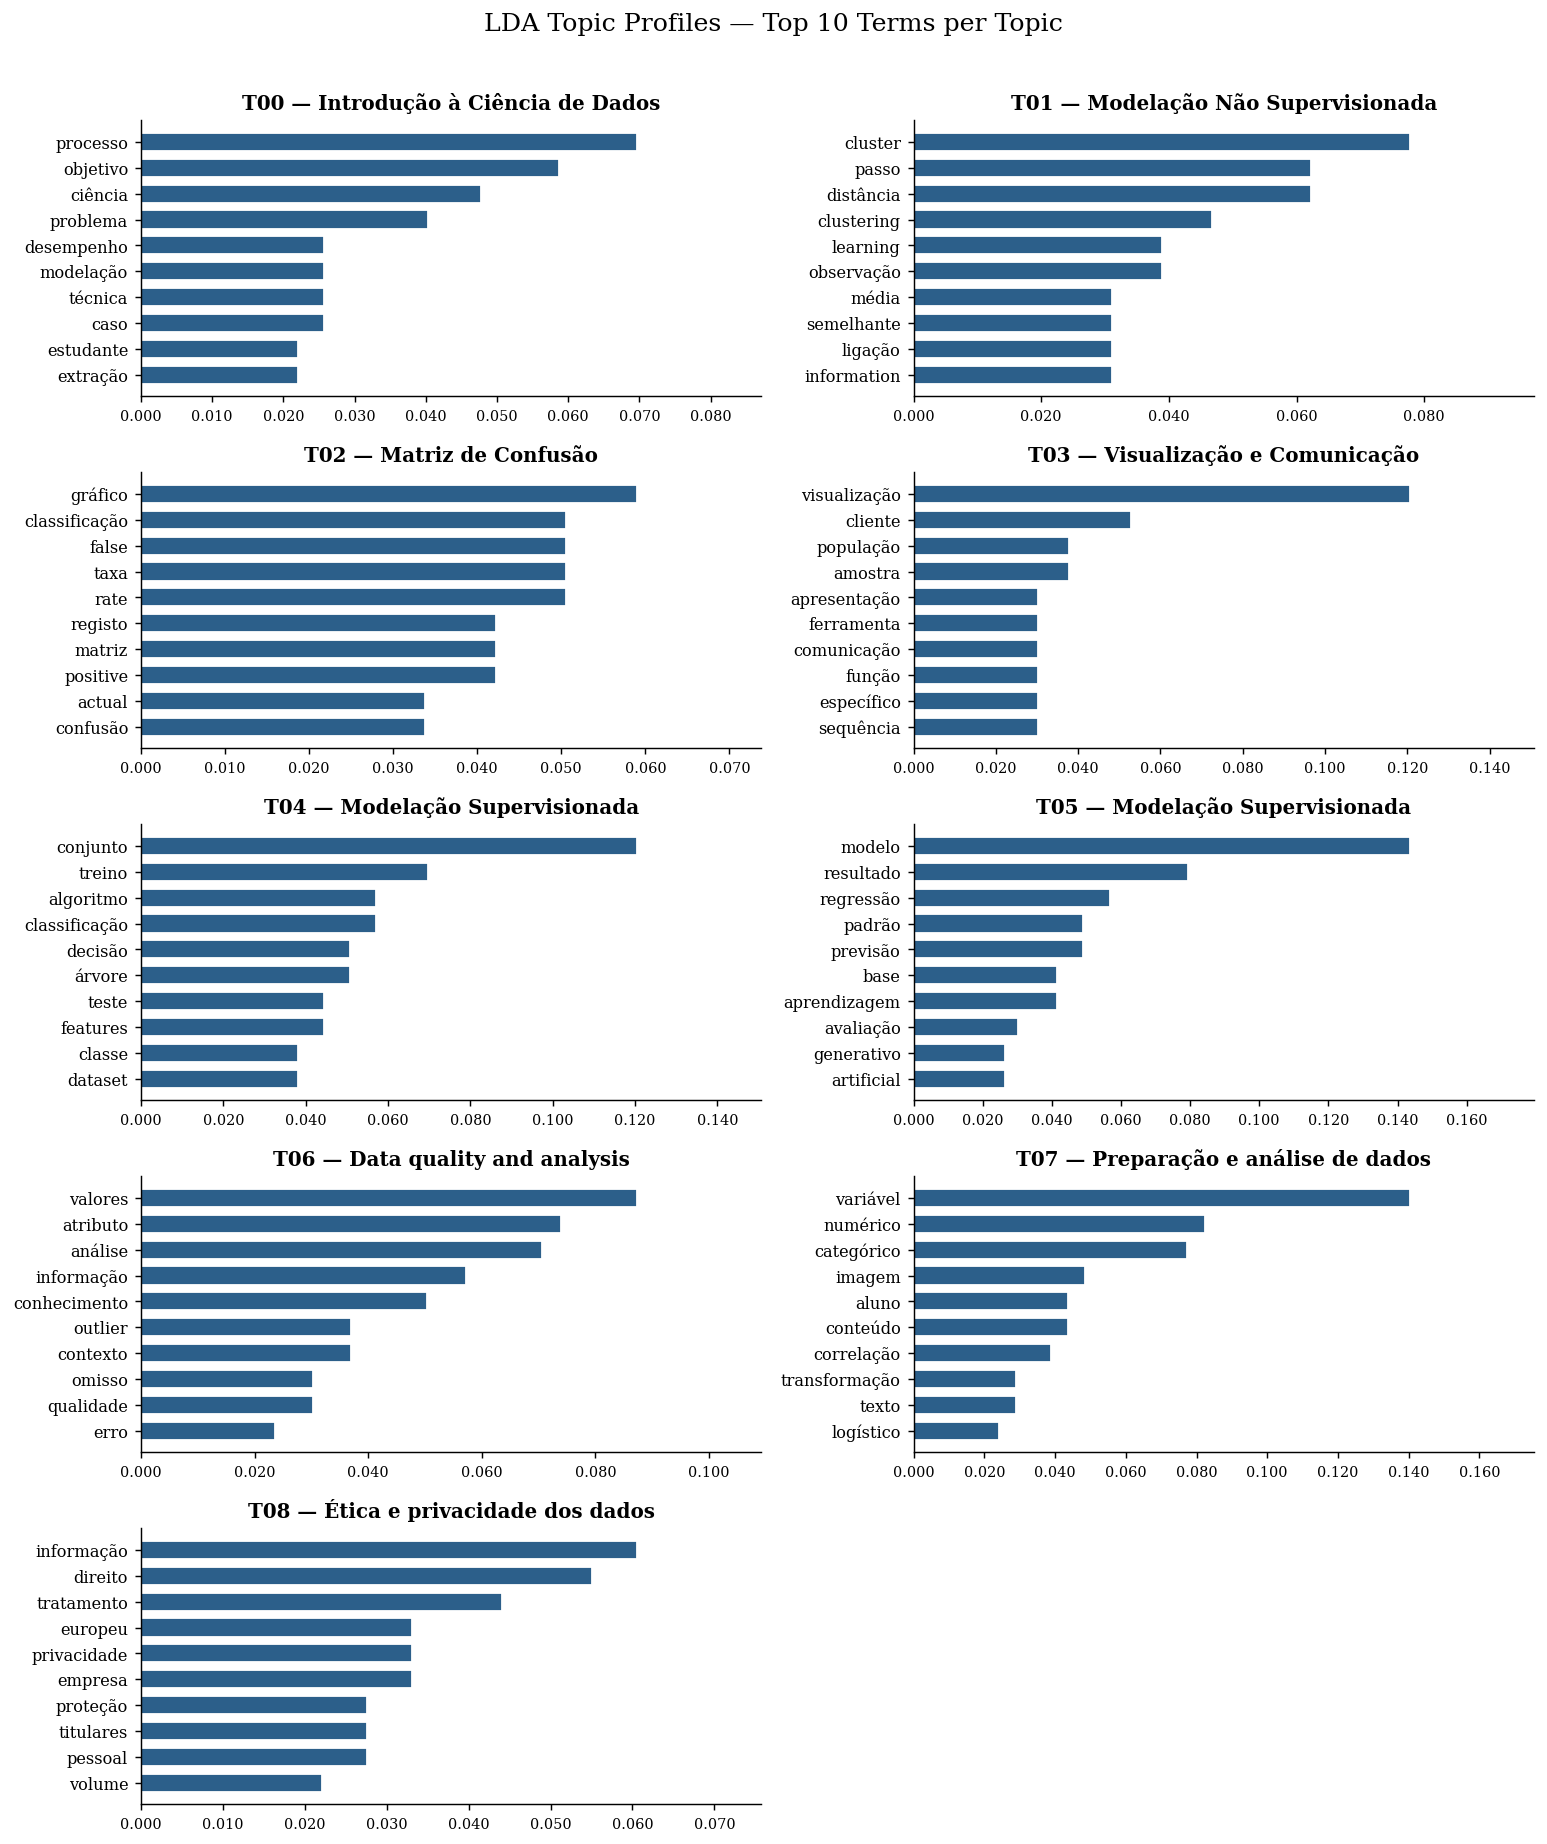

In [10]:
# Visualize topic profiles
TOP_VIS = 10
n_cols = 2
n_rows = (NUM_TOPICS + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 2.8))
axes = axes.flatten()

for i in range(NUM_TOPICS):
    terms = lda.get_topic_words(i, top_n=TOP_VIS)
    words   = [w for w, _ in terms][::-1]
    weights = [p for _, p in terms][::-1]

    ax = axes[i]
    ax.barh(words, weights, color=PALETTE[0], edgecolor='white', height=0.7)
    ax.set_title(f'T{i:02d} — {TOPIC_LABELS[i]}', fontsize=11, fontweight='bold')
    ax.set_xlim(0, max(weights) * 1.25)
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

# Hide unused subplots
for j in range(NUM_TOPICS, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('LDA Topic Profiles — Top 10 Terms per Topic', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

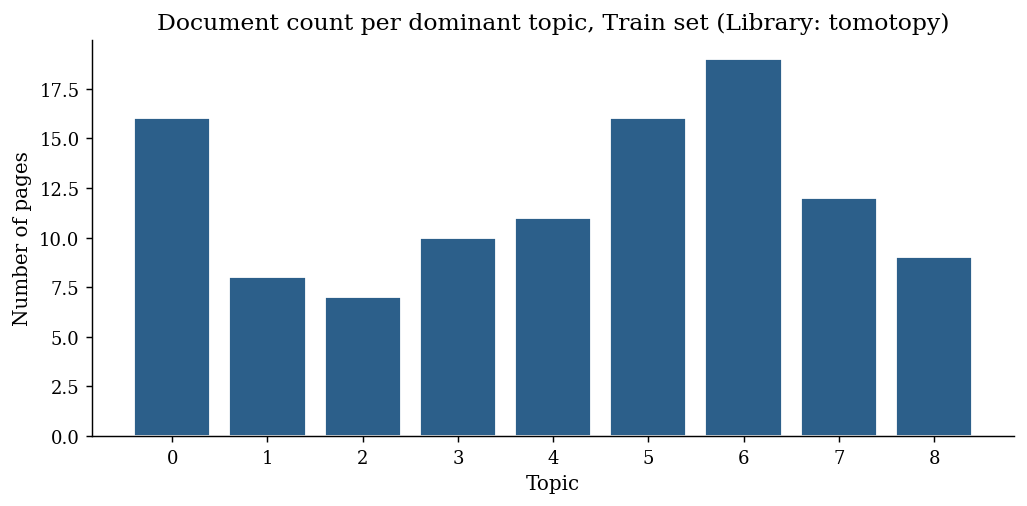

In [11]:
# Visualize document-topic distribution (Train)
train_df = train_df.copy()
train_df['dominant_topic'] = [
    int(np.argmax(doc.get_topic_dist())) for doc in lda.docs
]

topic_dist = train_df['dominant_topic'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(topic_dist.index, topic_dist.values, color=PALETTE[0], edgecolor='white')
ax.set_xlabel('Topic')
ax.set_ylabel('Number of pages')
ax.set_title('Document count per dominant topic, Train set (Library: tomotopy)')
ax.set_xticks(range(NUM_TOPICS))
plt.tight_layout()
plt.show()

## 5. Initial Evaluation (C_v)

In [12]:
from tomotopy.coherence import Coherence

coh = Coherence(lda, coherence='c_v')
coherence_cv = coh.get_score()

print(f'Coherence (C_v): {coherence_cv:.4f}  (target > 0.50)')

Coherence (C_v): 0.7863  (target > 0.50)


## 6. Grid Search — Finding the Best K

K initial = 9 (one per slide deck, domain-informed prior).  
Grid search over K ∈ [2, 12] to find the C_v-optimal K for this library.  
The best K from each library will be used in the cross-library comparison (Section 7).

k= 2  C_v=0.5292
k= 3  C_v=0.6513
k= 4  C_v=0.7256
k= 5  C_v=0.7329
k= 6  C_v=0.7341
k= 7  C_v=0.7491
k= 8  C_v=0.8049
k= 9  C_v=0.7863
k=10  C_v=0.7896
k=11  C_v=0.8070
k=12  C_v=0.8111


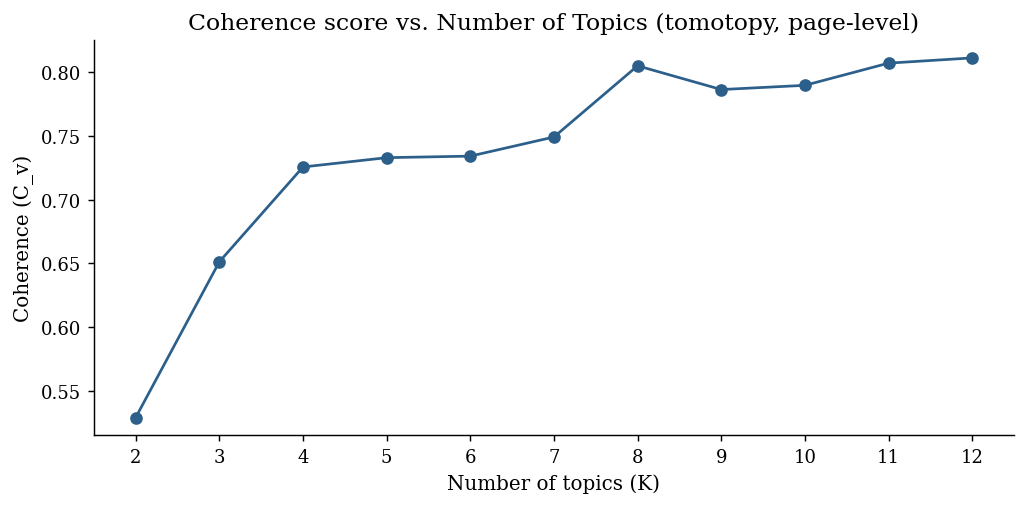


Best k=12  C_v=0.8111


In [13]:
from tomotopy.coherence import Coherence

TOPIC_RANGE = range(2, 13)

results = []
for k in TOPIC_RANGE:
    m = tp.LDAModel(k=k, alpha=ALPHA, eta=ETA, min_df=2, rm_top=0, seed=RANDOM_SEED)
    for token_list in train_texts:
        m.add_doc(token_list)
    m.train(0)
    m.train(ITERATIONS, workers=1)
    cv = Coherence(m, coherence='c_v').get_score()
    results.append({'k': k, 'coherence_cv': round(cv, 4)})
    print(f'k={k:2d}  C_v={cv:.4f}')

results_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(results_df['k'], results_df['coherence_cv'], marker='o', color=PALETTE[0])
ax.set_xlabel('Number of topics (K)')
ax.set_ylabel('Coherence (C_v)')
ax.set_title('Coherence score vs. Number of Topics (tomotopy, page-level)')
ax.set_xticks(list(TOPIC_RANGE))
plt.tight_layout()
plt.show()

best = results_df.loc[results_df['coherence_cv'].idxmax()]
print(f'\nBest k={int(best.k)}  C_v={best.coherence_cv}')

## 7. Cross-library Comparison

Trains models at three K values to compare how each library responds to K choices made by the other:
- **K_INITIAL**: domain-informed starting point
- **K_CGS_BEST**: optimal K found by tomotopy CGS grid search
- **K_VB_BEST**: optimal K found by gensim VB grid search

In [14]:
K_INITIAL  = 9   # domain-informed prior: one topic per slide deck
K_CGS_BEST = 8   # tomotopy CGS grid search optimum (C_v peak)
K_VB_BEST  = 3   # gensim VB grid search optimum (C_v peak)

K_GRID = [K_INITIAL, K_CGS_BEST, K_VB_BEST]

models_by_k = {}
for k in K_GRID:
    m = tp.LDAModel(k=k, alpha=ALPHA, eta=ETA, min_df=2, rm_top=0, seed=RANDOM_SEED)
    for token_list in train_texts:
        m.add_doc(token_list)
    m.train(0)
    m.train(ITERATIONS, workers=1)
    models_by_k[k] = m
    print(f'Trained tomotopy CGS  k={k}  C_v={Coherence(m, coherence="c_v").get_score():.4f}')

print('\nCross-library C_v summary:')
for label, k in [('K_INITIAL', K_INITIAL), ('K_CGS_BEST', K_CGS_BEST), ('K_VB_BEST', K_VB_BEST)]:
    cv = Coherence(models_by_k[k], coherence='c_v').get_score()
    print(f'  {label} (k={k}): C_v = {cv:.4f}')

Trained tomotopy CGS  k=9  C_v=0.7863
Trained tomotopy CGS  k=8  C_v=0.8049
Trained tomotopy CGS  k=3  C_v=0.6513

Cross-library C_v summary:
  K_INITIAL (k=9): C_v = 0.7863
  K_CGS_BEST (k=8): C_v = 0.8049
  K_VB_BEST (k=3): C_v = 0.6513


## 8. Final Evaluation

Evaluates the best model found by the grid search (K_CGS_BEST=8) with all metrics:
- **C_v coherence** (primary)
- **Test perplexity** (secondary)

In [15]:
best_model = models_by_k[K_CGS_BEST]

# C_v coherence
best_cv = Coherence(best_model, coherence='c_v').get_score()
print(f'Best model (k={K_CGS_BEST}) — C_v: {best_cv:.4f}')

# Train perplexity — tomotopy native (in-sample)
train_perplexity = np.exp(-best_model.ll_per_word)
print(f'Best model (k={K_CGS_BEST}) — Train Perplexity: {train_perplexity:.2f}')

# Test perplexity — tomotopy native (out-of-sample)
total_ll    = 0.0
total_words = 0
for token_list in test_texts:
    doc = best_model.make_doc(token_list)
    _, ll = best_model.infer(doc)
    total_ll    += ll
    total_words += len(token_list)

test_perplexity = np.exp(-total_ll / total_words)
print(f'Best model (k={K_CGS_BEST}) — Test Perplexity: {test_perplexity:.2f}')

Best model (k=8) — C_v: 0.8049
Best model (k=8) — Train Perplexity: 429.04
Best model (k=8) — Test Perplexity: 11.56


### 8.1 U_mass Coherence

In [16]:
from tomotopy.coherence import Coherence

coh_umass = Coherence(best_model, coherence='u_mass')
coherence_umass = coh_umass.get_score()

print(f'Best model (k={K_CGS_BEST}) — U_mass: {coherence_umass:.4f}  (closer to 0 = better; range typically −14 to 0)')

Best model (k=8) — U_mass: -8.0863  (closer to 0 = better; range typically −14 to 0)


In [17]:
# Topic diversity: fraction of unique words across top-N words of all topics
# Dieng et al. (2020) — range [0, 1]; higher = less redundancy between topics
TOP_N_DIV = 25

all_top_words = []
for i in range(K_CGS_BEST):
    terms = best_model.get_topic_words(i, top_n=TOP_N_DIV)
    all_top_words.extend([w for w, _ in terms])

diversity = len(set(all_top_words)) / len(all_top_words)
print(f'Best model (k={K_CGS_BEST}) — Topic Diversity (top-{TOP_N_DIV}): {diversity:.4f}  (range 0–1; higher = more diverse)')

Best model (k=8) — Topic Diversity (top-25): 0.9350  (range 0–1; higher = more diverse)


In [18]:
# Mean pairwise cosine similarity over top-N topic word-probability vectors
# Lower = more distinct topics; range [0, 1]
from itertools import combinations
import numpy as np

TOP_N_COS = 10
vocab_size = best_model.num_vocabs

# Build word -> index mapping from tomotopy's _VocabDict
word2idx = {w: i for i, w in enumerate(best_model.vocabs)}

# Build topic vectors (full vocab, probability at each position)
topic_vectors = []
for i in range(K_CGS_BEST):
    vec = np.zeros(vocab_size)
    for w, p in best_model.get_topic_words(i, top_n=TOP_N_COS):
        if w in word2idx:
            vec[word2idx[w]] = p
    topic_vectors.append(vec)

sims = []
for a, b in combinations(topic_vectors, 2):
    cos = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-10)
    sims.append(cos)

mean_cos = np.mean(sims)
max_cos  = np.max(sims)
print(f'Best model (k={K_CGS_BEST}) — Cosine Similarity (top-{TOP_N_COS}): mean={mean_cos:.4f}, max={max_cos:.4f}  (lower = more distinct)')

Best model (k=8) — Cosine Similarity (top-10): mean=0.0072, max=0.0872  (lower = more distinct)


In [19]:
# Shannon entropy of topic-word distributions
# Higher = more diffuse topic; lower = more concentrated/specific
from scipy.stats import entropy as shannon_entropy

entropies = []
for i in range(K_CGS_BEST):
    probs = np.array(best_model.get_topic_word_dist(i))  # full vocab distribution
    entropies.append(shannon_entropy(probs))

mean_ent = np.mean(entropies)
print(f'Best model (k={K_CGS_BEST}) — Shannon Entropy: mean={mean_ent:.4f}  (higher = more diffuse)')
for i, e in enumerate(entropies):
    print(f'  T{i+1}: {e:.4f}')

Best model (k=8) — Shannon Entropy: mean=3.8030  (higher = more diffuse)
  T1: 3.8887
  T2: 3.5189
  T3: 3.6425
  T4: 3.9263
  T5: 3.5185
  T6: 3.8292
  T7: 3.9336
  T8: 4.1660


In [20]:
# Exclusivity: mean P(topic|word) over top-N words per topic
# Higher = words concentrated in that topic alone; lower = words shared across topics
TOP_N_EXC = 10

# Compute P(word|topic) matrix for all topics
topic_word_matrix = np.array([best_model.get_topic_word_dist(i) for i in range(K_CGS_BEST)])
# P(topic|word) via Bayes: normalise across topics for each word
topic_given_word = topic_word_matrix / (topic_word_matrix.sum(axis=0, keepdims=True) + 1e-10)

exclusivities = []
for i in range(K_CGS_BEST):
    top_indices = topic_word_matrix[i].argsort()[-TOP_N_EXC:]
    excl = topic_given_word[i, top_indices].mean()
    exclusivities.append(excl)

mean_excl = np.mean(exclusivities)
print(f'Best model (k={K_CGS_BEST}) — Exclusivity (top-{TOP_N_EXC}): mean={mean_excl:.4f}  (higher = more exclusive)')
for i, e in enumerate(exclusivities):
    print(f'  T{i+1}: {e:.4f}')

Best model (k=8) — Exclusivity (top-10): mean=0.9097  (higher = more exclusive)
  T1: 0.8457
  T2: 0.9611
  T3: 0.8541
  T4: 0.9381
  T5: 0.9560
  T6: 0.8558
  T7: 0.9067
  T8: 0.9598


### 8.6 Evaluation Summary

In [21]:
summary = {
    'Metric': ['C_v', 'U_mass', 'Train Perplexity', 'Test Perplexity',
               'Diversity (top-25)', 'Cosine Sim (mean)', 'Shannon Entropy', 'Exclusivity (top-10)'],
    'CGS k=8': [f'{best_cv:.2f}', f'{coherence_umass:.2f}', f'{train_perplexity:.2f}',
                f'{test_perplexity:.2f}', f'{diversity:.2f}', f'{mean_cos:.3f}',
                f'{mean_ent:.2f}', f'{mean_excl:.2f}'],
    'Direction': ['higher', 'closer to 0', 'lower', 'lower', 'higher', 'lower', 'lower', 'higher'],
}

summary_df = pd.DataFrame(summary).set_index('Metric')
summary_df

,CGS k=8,Direction
Metric,,
C_v,0.80,higher
U_mass,-8.09,closer to 0
Train Perplexity,429.04,lower
Test Perplexity,11.56,lower
Diversity (top-25),0.94,higher
Cosine Sim (mean),0.007,lower
Shannon Entropy,3.80,lower
Exclusivity (top-10),0.91,higher
